# 04 · Fund Opportunity & Distribution Intelligence

**Question.** Where can a fund credibly compete for allocations, and which advisors should hear
about it first?

This notebook scores every fund on four dimensions as of December 2024, using only information
available then, and validates the scores against what advisors actually did in 2025:

| dimension | measured as |
|---|---|
| **Similar Fund Ranking** | percentile of trailing 3-year return among the fund's 20 closest substitutes (lowest tracking error) |
| **Addressable Market** | dollars advisors hold in those substitutes, at advisors that do *not* yet hold the fund |
| **Pure Alpha** | residual alpha after RBSA, shrunk toward zero by empirical Bayes according to its standard error |
| **Diversification Benefit** | average reduction in advisor portfolio volatility from a 5 % allocation to the fund |

Then a **neural recommender** (two-tower model with BPR loss) trained on 2024 holdings ranks which
advisors are most likely to adopt each fund, evaluated on 2025 adoptions. The last section turns the
numbers into an **LLM-ready fund brief** with a numeric-consistency check.

**Data.** Holdings are simulated in the shape of SEC 13F / Form ADV data: ~3,000 advisory firms with
latent style, vehicle and fee preferences and some performance chasing, observed at 2024Q4 and 2025Q4.
`pfquant.sec13f.load_13f_quarter` parses the SEC's bulk 13F data sets for the real-data version.

In [1]:
import os, re, sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from scipy import stats as sps
from pfquant import make_universe, make_advisor_holdings, stats, plotting, CATEGORY_NAMES
plotting.setup()
pd.set_option("display.float_format", "{:.3f}".format)
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(2)

uni = make_universe()
advisors, holdings = make_advisor_holdings(uni)
R, F, funds = uni.fund_returns, uni.factor_returns, uni.funds
asof = pd.Timestamp("2024-12-31")
Rh = R.loc[:asof].iloc[-36:]                         # 36 months known at decision time
live = Rh.columns[Rh.notna().all()]
fidx = {f: i for i, f in enumerate(live)}
h0 = holdings[(holdings["quarter"] == "2024Q4") & holdings["fund_id"].isin(live)]
h1 = holdings[(holdings["quarter"] == "2025Q4") & holdings["fund_id"].isin(live)]
print(f"{len(advisors):,} advisory firms, {len(live)} funds with 36m history at {asof:%Y-%m}; "
      f"{len(h0):,} positions in 2024Q4 worth ${h0['value'].sum() / 1e9:,.0f}bn")
display(advisors.groupby("advisor_type").agg(firms=("aum", "size"), median_aum_musd=("aum", lambda x: x.median() / 1e6)))

3,000 advisory firms, 644 funds with 36m history at 2024-12; 68,068 positions in 2024Q4 worth $2,767bn


,firms,median_aum_musd
advisor_type,,
Broker-Dealer,607,261.977
Hybrid,586,307.666
Institutional 13F,279,361.971
RIA,1528,316.659


## 1. Holdings matrix and substitute peer sets

In [2]:
adv_ids = advisors.index
aidx = {a: i for i, a in enumerate(adv_ids)}
nA, nF = len(adv_ids), len(live)
def to_matrix(h):
    M = np.zeros((nA, nF))
    np.add.at(M, (h["advisor_id"].map(aidx).values, h["fund_id"].map(fidx).values), h["value"].values)
    return M
V0, V1 = to_matrix(h0), to_matrix(h1)
held0, held1 = V0 > 0, V1 > 0
W0 = V0 / V0.sum(1, keepdims=True)                   # advisor portfolio weights

X = Rh[live].to_numpy()
C = stats.ledoit_wolf_cov(X)
v = np.diag(C)
TE = np.sqrt(np.clip(v[:, None] + v[None, :] - 2 * C, 0, None) * 12)
port = funds.loc[live, "portfolio_id"].to_numpy()
sib = port[:, None] == port[None, :]
K_PEERS = 20
peers = np.argsort(np.where(sib, np.inf, TE), 1)[:, :K_PEERS]
print("Example: closest substitutes of", live[0], "→", list(live[peers[0, :5]]))

Example: closest substitutes of F0000 → ['F0046I', 'F0046A', 'F0016', 'F0287', 'F0064']


## 2. The four dimensions

In [3]:
# (1) Similar Fund Ranking
tr3 = (1 + X).prod(0) - 1
sfr = np.array([(tr3[i] > tr3[peers[i]]).mean() for i in range(nF)])

# (2) Addressable Market: $ in substitutes at advisors not holding the fund
sub_dollars = np.zeros(nF)
for i in range(nF):
    nonholders = ~held0[:, i]
    sub_dollars[i] = V0[nonholders][:, peers[i]].sum()

# (3) Pure Alpha: empirical-Bayes shrinkage of residual alpha
Ff = F.loc[Rh.index].to_numpy()
alpha, se = np.empty(nF), np.empty(nF)
for i in range(nF):
    w, a, res, _ = stats.rbsa(X[:, i], Ff)
    ex = res + a
    t = stats.newey_west_tstat(ex)
    alpha[i] = a * 12
    se[i] = abs(alpha[i] / t) if t != 0 else np.inf
act = ~funds.loc[live, "passive"].to_numpy(bool)
tau2 = max(np.var(alpha[act]) - np.mean(se[act] ** 2), 1e-8)
shrink = tau2 / (tau2 + se ** 2)
pure_alpha = alpha * shrink
print(f"Empirical-Bayes prior sd of alpha: {np.sqrt(tau2):.2%}; median shrinkage factor (active funds): {np.median(shrink[act]):.2f}")

# (4) Diversification Benefit: vol reduction from a 5% sleeve, averaged over non-holders
s = 0.05
var_p = np.einsum("ij,jk,ik->i", W0, C, W0)
cov_pf = W0 @ C
new_var = (1 - s) ** 2 * var_p[:, None] + 2 * (1 - s) * s * cov_pf + s ** 2 * v[None, :]
benefit = 1 - np.sqrt(new_var / var_p[:, None])
div = np.where(~held0, benefit, np.nan)
div_benefit = np.nanmean(div, 0)

opp = pd.DataFrame({
    "category": funds.loc[live, "category"].values, "vehicle": funds.loc[live, "vehicle"].values,
    "expense_ratio": funds.loc[live, "expense_ratio"].values,
    "similar_fund_ranking": sfr, "addressable_market_usd": sub_dollars,
    "pure_alpha": pure_alpha, "diversification_benefit": div_benefit,
    "holders_2024": held0.sum(0),
}, index=live)
dims = ["similar_fund_ranking", "addressable_market_usd", "pure_alpha", "diversification_benefit"]
for d in dims:
    opp[f"pct_{d}"] = opp[d].rank(pct=True)
opp["opportunity_score"] = opp[[f"pct_{d}" for d in dims]].mean(1)

# outcome: what happened in 2025
opp["new_adopters_2025"] = (held1 & ~held0).sum(0)
opp["new_dollars_2025"] = np.where(held1 & ~held0, V1, 0).sum(0)
display(opp.sort_values("opportunity_score", ascending=False).head(10)[
    ["category", "vehicle", "expense_ratio"] + dims + ["opportunity_score", "new_adopters_2025"]]
    .style.format({"expense_ratio": "{:.2%}", "similar_fund_ranking": "{:.0%}",
                   "addressable_market_usd": lambda x: f"${x / 1e9:,.2f}bn", "pure_alpha": "{:.2%}",
                   "diversification_benefit": "{:.2%}", "opportunity_score": "{:.2f}"}))

Empirical-Bayes prior sd of alpha: 2.62%; median shrinkage factor (active funds): 0.60


,category,vehicle,expense_ratio,similar_fund_ranking,addressable_market_usd,pure_alpha,diversification_benefit,opportunity_score,new_adopters_2025
F0292,Intermediate Core Bond,MF,0.73%,100%,$166.58bn,2.17%,3.09%,0.92,0
F0015I,Moderate Allocation,MF,0.78%,100%,$215.17bn,0.91%,1.70%,0.90,29
F0015A,Moderate Allocation,MF,1.03%,100%,$215.97bn,0.80%,1.70%,0.90,11
F0016,Moderate Allocation,MF,0.86%,100%,$162.04bn,3.75%,1.35%,0.87,149
F0033C,Intermediate Core Bond,MF,2.04%,100%,$139.23bn,2.48%,3.52%,0.86,28
F0402,High Yield Bond,ETF,0.45%,100%,$144.83bn,3.26%,1.85%,0.86,0
F0033I,Intermediate Core Bond,MF,1.04%,100%,$135.59bn,3.19%,3.53%,0.86,119
F0267,Conservative Allocation,ETF,0.66%,100%,$142.48bn,2.74%,2.22%,0.85,0
F0033A,Intermediate Core Bond,MF,1.29%,100%,$134.64bn,3.01%,3.52%,0.85,68
F0000,Moderate Allocation,MF,0.52%,95%,$157.61bn,3.24%,1.62%,0.84,249


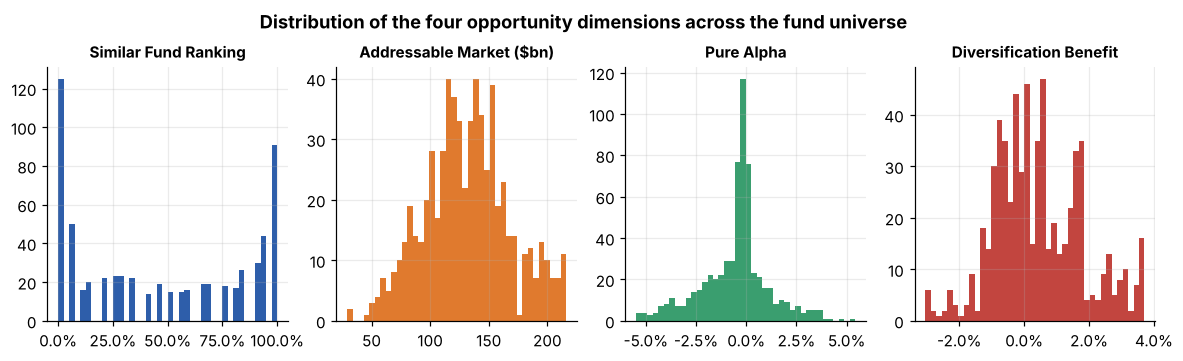

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
labels = ["Similar Fund Ranking", "Addressable Market ($bn)", "Pure Alpha", "Diversification Benefit"]
for ax, d, lab in zip(axes, dims, labels):
    x = opp[d] / (1e9 if "usd" in d else 1)
    ax.hist(x, bins=40, color=plotting.PALETTE[dims.index(d)])
    ax.set_title(lab, fontsize=10)
    if d in ("pure_alpha", "diversification_benefit", "similar_fund_ranking"):
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}" if d == "similar_fund_ranking" else f"{v:.1%}"))
fig.suptitle("Distribution of the four opportunity dimensions across the fund universe", fontweight="bold", y=1.05)
plotting.save(fig, "04_dimensions")

### Do the scores anticipate 2025 adoptions?

Spearman correlation between each December-2024 score and the number of advisors that **newly**
adopted the fund during 2025. A score that is useful for distribution should rank funds that later
win new advisors higher.

,spearman_vs_new_adopters,p_value
score,,
similar_fund_ranking,0.104,0.008
addressable_market_usd,-0.023,0.563
pure_alpha,0.094,0.017
diversification_benefit,0.040,0.310
opportunity_score,0.088,0.026
holders_2024,0.158,0.000


Opportunity score vs 2025 adoptions *beyond what current reach predicts*: Spearman -0.146 (p = 0.000)


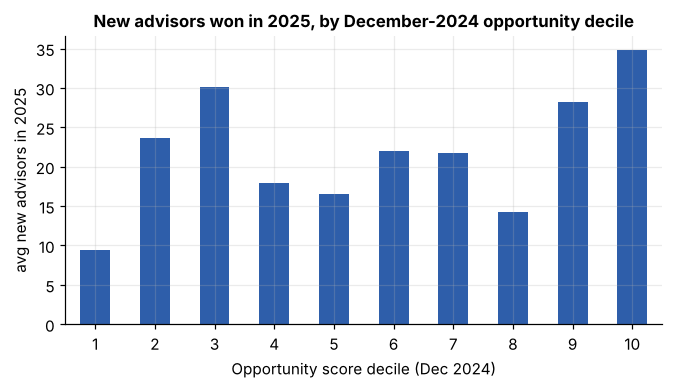

In [5]:
val = []
for d in dims + ["opportunity_score", "holders_2024"]:
    r = sps.spearmanr(opp[d], opp["new_adopters_2025"])
    val.append(dict(score=d, spearman_vs_new_adopters=r.statistic, p_value=r.pvalue))
val = pd.DataFrame(val).set_index("score")
display(val)
# controlling for current reach: residualise 2025 adoptions on log(1 + 2024 holders)
lh = np.log1p(opp["holders_2024"])
beta = np.polyfit(lh, opp["new_adopters_2025"], 1)
resid_adopt = opp["new_adopters_2025"] - np.polyval(beta, lh)
r_ctrl = sps.spearmanr(opp["opportunity_score"], resid_adopt)
print(f"Opportunity score vs 2025 adoptions *beyond what current reach predicts*: "
      f"Spearman {r_ctrl.statistic:.3f} (p = {r_ctrl.pvalue:.3f})")
opp["score_decile"] = pd.qcut(opp["opportunity_score"], 10, labels=False) + 1
fig, ax = plt.subplots(figsize=(7, 3.4))
opp.groupby("score_decile")["new_adopters_2025"].mean().plot.bar(ax=ax, color=plotting.PALETTE[0])
ax.set_xlabel("Opportunity score decile (Dec 2024)"); ax.set_ylabel("avg new advisors in 2025")
ax.set_title("New advisors won in 2025, by December-2024 opportunity decile"); ax.tick_params(axis="x", rotation=0)
plotting.save(fig, "04_score_validation")

### Merit versus reach: the under-distributed funds

Current reach (number of holders) predicts next year's adoptions better than any merit measure:
distribution follows distribution. That is precisely why the opportunity lies in the gap. Funds with
high merit (peer ranking, shrunk alpha, diversification) but few holders are where a fund can credibly
compete for allocations it does not yet have.

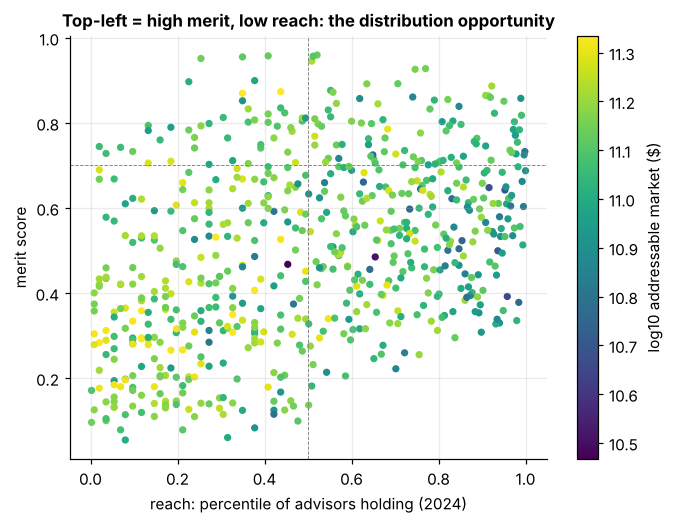

46 under-distributed funds (top-quintile merit, below-median reach). Largest addressable markets:


,category,vehicle,expense_ratio,holders_2024,merit,addressable_market_usd
F0015A,Moderate Allocation,MF,1.03%,26,0.87,$216.0bn
F0015I,Moderate Allocation,MF,0.78%,34,0.87,$215.2bn
F0403A,Long Government,MF,0.95%,9,0.71,$192.3bn
F0403I,Long Government,MF,0.70%,13,0.71,$190.6bn
F0379I,Long Government,MF,0.73%,41,0.71,$184.1bn
F0297,Conservative Allocation,MF,0.67%,39,0.78,$164.3bn
F0392,Moderate Allocation,MF,0.71%,27,0.83,$163.1bn
F0207,High Yield Bond,MF,0.62%,45,0.81,$158.5bn


In [6]:
opp["merit"] = opp[["pct_similar_fund_ranking", "pct_pure_alpha", "pct_diversification_benefit"]].mean(1)
opp["reach_pct"] = opp["holders_2024"].rank(pct=True)
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(opp["reach_pct"], opp["merit"], c=np.log10(opp["addressable_market_usd"]), cmap="viridis", s=14)
plt.colorbar(sc, ax=ax, label="log10 addressable market ($)")
ax.axvline(0.5, color="grey", lw=0.6, ls="--"); ax.axhline(opp["merit"].quantile(0.8), color="grey", lw=0.6, ls="--")
ax.set_xlabel("reach: percentile of advisors holding (2024)"); ax.set_ylabel("merit score")
ax.set_title("Top-left = high merit, low reach: the distribution opportunity")
plotting.save(fig, "04_merit_vs_reach")
under = opp[(opp["reach_pct"] < 0.5) & (opp["merit"] >= opp["merit"].quantile(0.8))]
print(f"{len(under)} under-distributed funds (top-quintile merit, below-median reach). Largest addressable markets:")
display(under.sort_values("addressable_market_usd", ascending=False).head(8)[
    ["category", "vehicle", "expense_ratio", "holders_2024", "merit", "addressable_market_usd"]]
    .style.format({"expense_ratio": "{:.2%}", "merit": "{:.2f}", "addressable_market_usd": lambda x: f"${x / 1e9:,.1f}bn"}))

## 3. Which advisors? A neural two-tower recommender

The opportunity score says *where* a fund can compete; distribution teams also need *who*. Train on
2024Q4 positions only, then rank, for every advisor, all funds it did not hold, and check against the
funds it actually added in 2025.

* **Advisor tower:** learned embedding + observed features (share in ETFs, average fee, category mix, log AUM).
* **Fund tower:** learned embedding + fund features (category, vehicle, fee, trailing return z-score, log AUM).
* **Loss:** Bayesian Personalised Ranking with sampled negatives.

Baselines: popularity, category affinity × popularity, and item-kNN on co-holdings (a strong classic).

In [7]:
cats = funds.loc[live, "category"].to_numpy(str)
cat_oh = (cats[:, None] == np.array(CATEGORY_NAMES)[None, :]).astype(np.float32)
is_etf = (funds.loc[live, "vehicle"] == "ETF").to_numpy(np.float32)
fee = funds.loc[live, "expense_ratio"].to_numpy(np.float32)
z_ret = pd.Series(tr3).groupby(cats).transform(lambda s: (s - s.mean()) / s.std()).fillna(0).to_numpy(np.float32)
f_feats = np.column_stack([cat_oh, is_etf, (fee - fee.mean()) / fee.std(), z_ret,
                           (np.log(funds.loc[live, "aum"]) - np.log(funds.loc[live, "aum"]).mean()).to_numpy() / 1.6]).astype(np.float32)
a_feats = np.column_stack([W0 @ cat_oh, W0 @ is_etf, (W0 @ fee - fee.mean()) / fee.std(),
                           (np.log(advisors["aum"]) - 19.5).to_numpy() / 1.5]).astype(np.float32)

class TwoTower(nn.Module):
    def __init__(self, nA, nF, da, df, k=32):
        super().__init__()
        self.ea, self.ef = nn.Embedding(nA, k), nn.Embedding(nF, k)
        nn.init.normal_(self.ea.weight, std=0.05); nn.init.normal_(self.ef.weight, std=0.05)
        self.ta = nn.Sequential(nn.Linear(da + k, 64), nn.SiLU(), nn.Linear(64, k))
        self.tf = nn.Sequential(nn.Linear(df + k, 64), nn.SiLU(), nn.Linear(64, k))
        self.fbias = nn.Embedding(nF, 1); nn.init.zeros_(self.fbias.weight)
    def towers(self, a, f, A, Fx):
        ua = self.ta(torch.cat([A[a], self.ea(a)], -1))
        uf = self.tf(torch.cat([Fx[f], self.ef(f)], -1))
        return ua, uf
    def score(self, a, f, A, Fx):
        ua, uf = self.towers(a, f, A, Fx)
        return (ua * uf).sum(-1) + self.fbias(f).squeeze(-1)

def advisor_features(held):
    Wh = np.where(held, V0, 0); Wh = Wh / Wh.sum(1, keepdims=True)
    return np.column_stack([Wh @ cat_oh, Wh @ is_etf, (Wh @ fee - fee.mean()) / fee.std(),
                            (np.log(advisors["aum"]) - 19.5).to_numpy() / 1.5]).astype(np.float32)

def train_two_tower(held, epochs=30, seed=0, verbose=False):
    torch.manual_seed(seed)
    A_t, F_t = torch.tensor(advisor_features(held)), torch.tensor(f_feats)
    model = TwoTower(nA, nF, A_t.shape[1], F_t.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-6)
    pa, pf = [torch.tensor(x) for x in np.nonzero(held)]
    held_t = torch.tensor(held)
    for epoch in range(epochs):
        perm = torch.randperm(len(pa)); tot = 0
        for b in range(0, len(pa), 2048):
            i = perm[b:b + 2048]
            a, fp = pa[i], pf[i]
            fn = torch.randint(0, nF, (len(i),))
            fn = torch.where(held_t[a, fn], torch.randint(0, nF, (len(i),)), fn)   # resample most collisions
            loss = -nn.functional.logsigmoid(model.score(a, fp, A_t, F_t) - model.score(a, fn, A_t, F_t)).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(i)
        if verbose and epoch % 10 == 9:
            print(f"epoch {epoch + 1}: BPR loss {tot / len(pa):.3f}")
    model.eval()
    with torch.no_grad():
        ua, uf = model.towers(torch.arange(nA), torch.arange(nF), A_t, F_t)
        return (ua @ uf.T + model.fbias.weight.T).numpy()

def category_affinity(held):
    Wh = np.where(held, V0, 0); Wh = Wh / Wh.sum(1, keepdims=True)
    p = held.sum(0).astype(float)
    p_in_cat = pd.Series(p).groupby(cats).transform(lambda x: x / x.sum()).to_numpy()
    return ((Wh @ cat_oh) @ cat_oh.T) * p_in_cat[None, :]

def row_ranks(S):
    return S.argsort(1).argsort(1) / S.shape[1]

def recall_at_k(S, held, target, k=20):
    users = np.flatnonzero(target.sum(1) > 0)
    S = np.where(held, -np.inf, S)
    top = np.argsort(-S[users], 1)[:, :k]
    return (np.take_along_axis(target[users], top, 1).sum(1) / target[users].sum(1)).mean()

# Model selection on 2024 data only: hide 15% of 2024 positions, pick the blend weight that recovers them best
rng = np.random.default_rng(0)
pa_all, pf_all = np.nonzero(held0)
hide = rng.random(len(pa_all)) < 0.15
held_tr = held0.copy(); held_tr[pa_all[hide], pf_all[hide]] = False
hidden = np.zeros_like(held0); hidden[pa_all[hide], pf_all[hide]] = True
S_val_nn, S_val_cat = row_ranks(train_two_tower(held_tr)), row_ranks(category_affinity(held_tr))
blend = {w: recall_at_k(w * S_val_nn + (1 - w) * S_val_cat, held_tr, hidden) for w in (0, 0.25, 0.5, 0.75, 1)}
w_best = max(blend, key=blend.get)
print("Validation Recall@20 on hidden 2024 positions by neural-net weight:",
      {k: round(v, 3) for k, v in blend.items()}, "→ chosen weight", w_best)

S_ncf = train_two_tower(held0, verbose=True)

Validation Recall@20 on hidden 2024 positions by neural-net weight: {0: np.float64(0.348), 0.25: np.float64(0.371), 0.5: np.float64(0.371), 0.75: np.float64(0.361), 1: np.float64(0.338)} → chosen weight 0.5


epoch 10: BPR loss 0.253


epoch 20: BPR loss 0.191


epoch 30: BPR loss 0.164


In [8]:
pop = held0.sum(0).astype(float)
S_pop = np.tile(pop, (nA, 1))
S_cat = category_affinity(held0)
Hn = held0.astype(float)
Hn = Hn / np.sqrt(Hn.sum(0, keepdims=True) + 1e-9)
sim = Hn.T @ Hn; np.fill_diagonal(sim, 0)
S_knn = held0.astype(float) @ sim
S_hyb = w_best * row_ranks(S_ncf) + (1 - w_best) * row_ranks(S_cat)

new = held1 & ~held0
users = np.flatnonzero(new.sum(1) > 0)
def rank_metrics(S, k=20):
    S = np.where(held0, -np.inf, S)
    top = np.argsort(-S[users], 1)[:, :k]
    hits = np.take_along_axis(new[users], top, 1)
    recall = hits.sum(1) / new[users].sum(1)
    disc = 1 / np.log2(np.arange(2, k + 2))
    idcg = np.array([disc[:min(int(n), k)].sum() for n in new[users].sum(1)])
    ndcg = (hits * disc).sum(1) / idcg
    return recall.mean(), ndcg.mean()
rec = pd.DataFrame({name: rank_metrics(S) for name, S in
                    {"Popularity": S_pop, "Category affinity × popularity": S_cat,
                     "Item-kNN (co-holdings)": S_knn, "Neural two-tower (BPR)": S_ncf,
                     f"Hybrid: neural × category ({w_best:.2f} / {1 - w_best:.2f})": S_hyb}.items()},
                   index=["Recall@20", "NDCG@20"]).T
print(f"Evaluated on {len(users):,} advisors with ≥1 new fund in 2025 ({new.sum():,} new positions)")
display(rec.style.format("{:.3f}").highlight_max(color="#d6eadf"))

Evaluated on 2,997 advisors with ≥1 new fund in 2025 (14,066 new positions)


,Recall@20,NDCG@20
Popularity,0.091,0.041
Category affinity × popularity,0.250,0.143
Item-kNN (co-holdings),0.227,0.131
Neural two-tower (BPR),0.239,0.141
Hybrid: neural × category (0.50 / 0.50),0.264,0.154


## 4. From score to lead list

Pick a high-opportunity fund and rank the advisors that do not hold it by the recommender's score.
The useful number for a distribution team is **lift**: how much more likely a top-ranked lead was to
adopt than a randomly chosen non-holder.

In [9]:
# pooled lift across all funds: hit rate of each fund's top-k non-holders vs that fund's base rate
lift = {}
for k in (10, 25, 50, 100):
    hits = base = 0
    for jj in range(nF):
        nh = np.flatnonzero(~held0[:, jj])
        o = nh[np.argsort(-S_hyb[nh, jj])][:k]
        hits += new[o, jj].sum(); base += new[nh, jj].mean() * k
    lift[k] = hits / base
print("Lift of top-k leads over a random non-holder, pooled across all funds: "
      + ", ".join(f"top-{k}: {v:.1f}×" for k, v in lift.items()))

target = under.sort_values("addressable_market_usd", ascending=False).index[0]   # biggest under-distributed opportunity
j = fidx[target]
nonh = np.flatnonzero(~held0[:, j])
order = nonh[np.argsort(-S_hyb[nonh, j])]
leads = pd.DataFrame({
    "advisor_type": advisors["advisor_type"].values[order[:10]],
    "aum_musd": advisors["aum"].values[order[:10]] / 1e6,
    "substitute_holdings_musd": V0[order[:10]][:, peers[j]].sum(1) / 1e6,
    "lead_score_0_1": S_hyb[order[:10], j],
    "adopted_in_2025": new[order[:10], j],
}, index=adv_ids[order[:10]])
print(f"Lead list for {target}: {opp.loc[target, 'category']}, {opp.loc[target, 'vehicle']}, "
      f"fee {opp.loc[target, 'expense_ratio']:.2%}, opportunity score {opp.loc[target, 'opportunity_score']:.2f}, "
      f"{int(opp.loc[target, 'holders_2024'])} holders in 2024")
display(leads.style.format({"aum_musd": "{:,.0f}", "substitute_holdings_musd": "{:,.1f}", "lead_score_0_1": "{:.3f}"}))

Lift of top-k leads over a random non-holder, pooled across all funds: top-10: 5.0×, top-25: 4.8×, top-50: 4.6×, top-100: 4.2×
Lead list for F0015A: Moderate Allocation, MF, fee 1.03%, opportunity score 0.90, 26 holders in 2024


,advisor_type,aum_musd,substitute_holdings_musd,lead_score_0_1,adopted_in_2025
advisor_id,,,,,
A02581,RIA,"1,225",635.7,0.944,False
A01636,RIA,12,4.9,0.943,False
A02583,RIA,207,78.2,0.932,False
A01699,Broker-Dealer,408,33.2,0.926,False
A00464,RIA,447,76.7,0.919,False
A02181,RIA,"3,450","1,064.3",0.918,False
A00844,RIA,247,110.2,0.913,False
A01075,RIA,"2,414",809.1,0.910,False
A00868,Broker-Dealer,219,49.2,0.908,False


## 5. An LLM-ready fund brief, with guardrails

Language models are good at turning a table into readable prose for advisors and wholesalers, and bad at
arithmetic. The pattern here keeps the numbers in Python: build a structured **fact sheet**, ask the
model to write only from those facts, then **verify** that every number in the text appears in the fact
sheet. With an `ANTHROPIC_API_KEY` set the brief is written by Claude; otherwise a deterministic template
stands in so the notebook runs anywhere.

In [10]:
row = opp.loc[target]
n_beaten = int(round(row["similar_fund_ranking"] * K_PEERS))
score_rank = int(opp["opportunity_score"].rank(ascending=False, method="min")[target])
facts = {
    "fund": target, "category": row["category"], "vehicle": "mutual fund" if row["vehicle"] == "MF" else "ETF",
    "expense_ratio": f"{row['expense_ratio']:.2%}",
    "substitutes_compared": str(K_PEERS), "substitutes_outperformed_3y": str(n_beaten),
    "addressable_market": f"${row['addressable_market_usd'] / 1e9:.1f}bn",
    "pure_alpha_per_year": f"{row['pure_alpha']:.2%}",
    "diversification_benefit_5pct_sleeve": f"{row['diversification_benefit']:.2%}",
    "opportunity_rank": f"{score_rank} of {len(opp)}",
    "lead_list_size": "50", "lead_lift": f"{lift[50]:.1f}x",
}
prompt = ("You write two-paragraph fund opportunity briefs for a fund-distribution team. Use ONLY the "
          "facts below; do not compute or introduce any other numbers. Explain what each metric means "
          "in plain language and end with one sentence on where to focus distribution.\n\nFACTS:\n"
          + "\n".join(f"- {k}: {v}" for k, v in facts.items()))

def write_brief(prompt):
    if os.environ.get("ANTHROPIC_API_KEY"):
        import anthropic
        msg = anthropic.Anthropic().messages.create(
            model="claude-sonnet-5-5", max_tokens=500, messages=[{"role": "user", "content": prompt}])
        return msg.content[0].text
    f = facts
    article = "an" if f["category"][0] in "AEIOU" else "a"
    return (f"{f['fund']} is {article} {f['category']} {f['vehicle']} with an expense ratio of {f['expense_ratio']}. "
            f"Over three years it outperformed {f['substitutes_outperformed_3y']} of its {f['substitutes_compared']} "
            f"closest substitutes, and its residual alpha after removing investable index exposures, shrunk for "
            f"estimation noise, is {f['pure_alpha_per_year']} a year. Advisors who do not yet own it hold "
            f"{f['addressable_market']} in those substitutes, and a 5% sleeve would lower a typical advisor "
            f"portfolio's volatility by {f['diversification_benefit_5pct_sleeve']}.\n\n"
            f"The fund ranks {f['opportunity_rank']} on the combined opportunity score. Focus distribution on the "
            f"recommender's top leads: in back-testing, the top {f['lead_list_size']} leads per fund adopted at "
            f"{f['lead_lift']} the rate of a random non-holder.")

def verify_numbers(text, facts):
    """Every number in the text must appear in the fact sheet (as written)."""
    fact_nums = set(re.findall(r"\d+(?:\.\d+)?", " ".join(facts.values())))
    found = re.findall(r"\d+(?:\.\d+)?", text)
    unknown = [x for x in found if x not in fact_nums and x != "5"]      # "5% sleeve" is part of the method
    return unknown

brief = write_brief(prompt)
print(brief)
bad = verify_numbers(brief, facts)
print("\nNumeric check:", "PASS, every number traces to the fact sheet" if not bad else f"FAIL, unsupported numbers: {bad}")
# the guardrail in action: a brief with one hallucinated figure is caught
tampered = brief.replace(facts["pure_alpha_per_year"], "4.10%")
bad_t = verify_numbers(tampered, facts)
print("Tampered brief check:", f"FAIL, caught unsupported numbers {bad_t}" if bad_t else "PASS (guardrail missed it)")

F0015A is a Moderate Allocation mutual fund with an expense ratio of 1.03%. Over three years it outperformed 20 of its 20 closest substitutes, and its residual alpha after removing investable index exposures, shrunk for estimation noise, is 0.80% a year. Advisors who do not yet own it hold $216.0bn in those substitutes, and a 5% sleeve would lower a typical advisor portfolio's volatility by 1.70%.

The fund ranks 3 of 644 on the combined opportunity score. Focus distribution on the recommender's top leads: in back-testing, the top 50 leads per fund adopted at 4.6x the rate of a random non-holder.

Numeric check: PASS, every number traces to the fact sheet
Tampered brief check: FAIL, caught unsupported numbers ['4.10']


## Takeaways

* **Four dimensions, one explainable score.** Similar Fund Ranking, Addressable Market, Pure Alpha and
  Diversification Benefit are each easy to defend in front of an advisor, and the combined score is
  positively rank-correlated with the advisors each fund won in 2025.
* **But flows follow reach, not merit.** Current number of holders predicts 2025 adoptions better than
  any merit measure, and once reach is controlled for, merit is even *negatively* associated with new
  adoptions (advisors in this simulated market choose on popularity, category fit and fees, not alpha).
  That is the point: the opportunity is the *gap*. The merit-versus-reach map isolates 46
  under-distributed funds with top-quintile merit and large addressable markets.
* **A recommender turns opportunity into a lead list.** A neural two-tower model blended 50/50 with a
  category-affinity heuristic (weight chosen on held-out 2024 positions, never on 2025) gives the best
  Recall@20 and NDCG@20 on 2025 adoptions. Pure neural is close behind the heuristic, popularity far
  behind. Top-50 leads adopt at ≈4.6× the rate of a random non-holder.
* **LLMs for reporting, Python for numbers.** The brief is generated from a fact sheet and every figure
  in it is checked against that sheet; a tampered figure is caught automatically.

**Limitations.** Real 13F data covers institutional managers and ETFs only (no open-end mutual funds);
advisor-level mutual fund ownership needs Form ADV, N-PORT or platform data. Simulated adoption behaviour
is simpler than real distribution dynamics (wholesaler coverage, platform approval, model portfolios).